# A1 · YOLO26-seg **agnóstico** (Propuesta 1: segmentador) — versión Colab + Drive

Entrena YOLO26-seg con **una sola clase («food»)**: solo aprende *dónde* hay comida y con qué máscara. Las categorías las asignará después un clasificador (cuadernillos C1–C4).

**Cómo se alimenta (todo desde tu Google Drive):**

| Archivo en Drive | Para qué |
|---|---|
| `food-recognition-2022.zip` | Imágenes originales (el 00 no las incluye) |
| `food-prep-v21.zip` | Salida del 00: `classes.json`, `splits.json`, `coco_*.json`, `manifest.json` (los recortes se omiten al extraer: este cuadernillo no los usa) |
| `food_utils_final.py` | Utilidades comunes (se copia como `food_utils.py`) |

El cuadernillo los **busca por nombre** en tu Drive (carpeta `calorie_counter` y `MyDrive`, hasta 3 niveles). Si no los encuentra, intenta bajarlos con `gdown` usando los ids de los enlaces compartidos. Los zips se extraen en el disco local de Colab (`/content/data`), que es mucho más rápido que leer imágenes desde Drive; los **pesos y resultados** sí se guardan en Drive para sobrevivir a una desconexión.

**Qué hace**
1. Prepara los datos (busca, extrae y valida) y carga `food_utils.Prep`, excluyendo las fotos con geometría irreconciliable.
2. Exporta el COCO a formato YOLO-seg (polígonos fusionados) en disco local.
3. **Entrena** `yolo26{tamaño}-seg` con reanudación segura (marcador `DONE.json`).
4. *(Opcional, secciones 3–5)* Predice en **val** y **test**, evalúa con `pycocotools` (AP de máscara de «comida»), mide parámetros y latencia y escribe `resultados/A1_*.json` para el cuadernillo 99.

> **Modo piloto (`CFG["pilot"]=True`, activo por defecto).** Entrena 1 época con el 5 % de los datos y evalúa 50 imágenes por split. Sirve para comprobar que *todo* el flujo funciona y estimar el tiempo por época antes del entrenamiento real. Los resultados del piloto van a `resultados_pilot/`, nunca a `resultados/`. Cuando todo funcione, pon `pilot=False` y ejecuta de nuevo.

> **Solo entrenar.** Si solo quieres el modelo entrenado, ejecuta hasta la sección 2 (la celda que imprime `Pesos: ...best.pt`) y detente: las secciones 3–5 son evaluación y se pueden correr después.

> **Equidad.** YOLO26 parte de pesos preentrenados en COCO (igual que Mask R-CNN y los demás segmentadores). Esto debe declararse en el informe: no es entrenamiento «desde cero».

In [1]:
import os, sys, re, json, time, glob, shutil, subprocess, importlib
from pathlib import Path
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("ultralytics", "pycocotools", "gdown"): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)

Mounted at /content/drive
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Datos desde Drive

Busca los tres archivos, extrae los dos zips en `DATA` (se omite si ya están extraídos en esta sesión) y localiza las carpetas que necesita `food_utils`. Si algún archivo tiene otro nombre o está en otra carpeta, indica su ruta en `DRIVE_PATHS`.

In [2]:
# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(raw=None, prep=None, utils=None)
# Ids de los enlaces compartidos (solo se usan si el archivo no aparece en tu Drive montado)
DRIVE_IDS = dict(raw="17y2oraB_OmagwpnTuiEnBvMPeQlg4nEY", prep="1LmD3j5smb-1NJp4hV0yAagvb7__rT--A", utils="1-9FZCbvzSxJdhq4Z9C8nnbd13Unga8NM")
PATTERNS  = dict(raw=r"food[-_ ]?recognition[-_ ]?2022.*\.zip$", prep=r"food[-_ ]?prep[-_ ]?v21.*\.zip$", utils=r"^food_utils.*\.py$")
OUT_NAMES = dict(raw="food-recognition-2022.zip", prep="food-prep-v21.zip", utils="food_utils.py")

def find_in_drive(kind, max_depth=3):
    pat = re.compile(PATTERNS[kind], re.I)
    roots = [WORK, Path("/content/drive/MyDrive"), Path.cwd()]
    for root in roots:
        if not root.exists(): continue
        base = len(root.parts)
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in ("runs", "yolo_data", "predicciones", "resultados", "Trash")]
            if len(Path(dp).parts) - base >= max_depth: dn[:] = []
            for f in fn:
                if pat.search(f): return Path(dp) / f
    return None

def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p
    p = find_in_drive(kind)
    if p: print(f"[{kind}] encontrado en Drive → {p}"); return p
    out = DATA / "zips" / OUT_NAMES[kind]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en el Drive montado; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        raise RuntimeError(f"No pude obtener '{kind}'. Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS "
                           f"(gdown falla a menudo en archivos grandes por la cuota de descargas de Drive).")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")
    if free < 1.5 * need: print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")
    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        if len(Path(dp).parts) - base >= max_depth: dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) imágenes originales
z_raw = get_file("raw");  print("→ extrayendo imágenes originales"); unzip_once(z_raw, DATA / "raw")
RAW_DIR = find_dir(DATA / "raw", lambda dn, fn: "public_training_set_release_2.0" in dn)
assert RAW_DIR is not None, "El zip original no contiene la carpeta public_training_set_release_2.0"
for k, sub in (("train", "public_training_set_release_2.0"), ("val", "public_validation_set_2.0")):
    d = RAW_DIR / sub / "images"; assert d.exists(), f"Falta {d}"
    print(f"   imágenes {k}: {sum(1 for _ in os.scandir(d)):,}")

# 2) salida del cuadernillo 00 (se omiten los recortes: A1 no los usa)
z_prep = get_file("prep"); print("→ extrayendo food-prep-v21 (sin recortes)"); unzip_once(z_prep, DATA / "prep", exclude=("crops/*", "*/crops/*"))
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json", "coco_train.json", "coco_val.json", "coco_test.json", "coco_agnostic_train.json") if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"

# 3) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nRAW_DIR :", RAW_DIR, "\nPREP_DIR:", PREP_DIR, "\nutils   :", CODE / "food_utils.py")

[raw] encontrado en Drive → /content/drive/MyDrive/calorie_counter/Food_Recognition_2022.zip
→ extrayendo imágenes originales
   zip 5.27 GB | espacio libre 252.9 GB
   extraído en 157 s
   imágenes train: 39,962
   imágenes val: 1,000
[prep] no está en el Drive montado; intento bajarlo con gdown (id 1LmD3j5smb-1NJp4hV0yAagvb7__rT--A)...


Downloading...
From (original): https://drive.google.com/uc?id=1LmD3j5smb-1NJp4hV0yAagvb7__rT--A
From (redirected): https://drive.google.com/uc?id=1LmD3j5smb-1NJp4hV0yAagvb7__rT--A&confirm=t&uuid=ab5b250e-f531-47a5-96da-e27ec7946d7f
To: /content/data/zips/food-prep-v21.zip
100%|██████████| 2.46G/2.46G [00:43<00:00, 55.9MB/s]


→ extrayendo food-prep-v21 (sin recortes)
   zip 2.46 GB | espacio libre 239.5 GB
   extraído en 23 s
[utils] encontrado en Drive → /content/drive/MyDrive/calorie_counter/food_utils.py

RAW_DIR : /content/data/raw/raw_data 
PREP_DIR: /content/data/prep 
utils   : /content/data/code/food_utils.py


In [3]:
import food_utils as fu
import ultralytics
print("food_utils", fu.__version__, "| ultralytics", ultralytics.__version__)

CFG = dict(
    base_id    = "A1",
    agnostic   = True,
    model_size = "m",        # n | s | m | l | x  (A1 y B1 deben usar el MISMO tamaño)
    imgsz      = 640,
    epochs     = 40,
    patience   = 10,
    batch      = 16,
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    conf       = 0.001,      # umbral para evaluar AP (estándar COCO)
    conf_latency = 0.25,     # umbral para medir latencia (uso real)
    max_det    = 100,
    eval_folds = 5,
    pilot      = False,       # <-- ponlo en False para el entrenamiento real
    prep_dir   = str(PREP_DIR),   # carpeta con classes.json / splits.json / coco_*.json (extraída arriba)
    raw_dir    = str(RAW_DIR),    # carpeta que contiene public_training_set_release_2.0
)
CFG["weights"] = f"yolo26{CFG['model_size']}-seg.pt"
CFG["exp_id"]  = f"{CFG['base_id']}_yolo26{CFG['model_size']}"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
print("Experimento:", RUN_NAME, "| pesos iniciales:", CFG["weights"])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
food_utils 0.1.0 | ultralytics 8.4.203
Experimento: A1_yolo26m | pesos iniciales: yolo26m-seg.pt


In [4]:
try:
    import torch
    CUDA = torch.cuda.is_available()
except ImportError:
    torch, CUDA = None, False
DEVICE = 0 if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
print("Dispositivo:", GPU)
if not CUDA:
    print("⚠️ Sin GPU: el entrenamiento real no es viable. Activa una GPU en Colab.")

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"], raw_dir=CFG["raw_dir"])
print(prep.summary())
BAD = {s: prep.bad_image_ids(s) for s in ("train", "val", "test")}
print("Imágenes excluidas por geometría irreconciliable:", {s: len(v) for s, v in BAD.items()})

Dispositivo: Tesla T4
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
Imágenes excluidas por geometría irreconciliable: {'train': 0, 'val': 0, 'test': 0}


## 1. Exportar a formato YOLO

Las imágenes se enlazan (no se copian) y las etiquetas usan los polígonos **fusionados** de cada instancia. El directorio YOLO va en disco local (se regenera en segundos), no en Drive.

In [5]:
YOLO_ROOT = Path("/content/yolo_data") if IN_COLAB else WORK / "yolo_data"
YOLO_DIR = YOLO_ROOT / ("agn" if CFG["agnostic"] else "cls")
exp = fu.export_yolo_seg(prep, YOLO_DIR, agnostic=CFG["agnostic"], exclude_ids=BAD)
DATA_YAML = exp["yaml"]
for s, st in exp["stats"].items(): print(f"[{s}]", st)
print("data.yaml:", DATA_YAML)

[train] {'images': 35195, 'instances': 66033, 'merged_multipolygon': 8102, 'excluded': 0}
[val] {'images': 946, 'instances': 1708, 'merged_multipolygon': 289, 'excluded': 0}
[test] {'images': 3911, 'instances': 7405, 'merged_multipolygon': 926, 'excluded': 0}
data.yaml: /content/yolo_data/agn/data.yaml


## 2. Entrenamiento

- **Reanudación segura:** si existe `DONE.json` no se vuelve a entrenar; si hay `last.pt` pero no `DONE.json`, se **reanuda** (esto evita dar por terminado un entrenamiento cortado por una desconexión).
- En modo piloto se entrena 1 época con el 5 % de los datos y se estima el tiempo por época.

In [6]:
from ultralytics import YOLO
import pandas as pd

PROJECT = WORK / "runs"
RUN_DIR = PROJECT / RUN_NAME
DONE = RUN_DIR / "DONE.json"

train_args = dict(data=DATA_YAML, imgsz=CFG["imgsz"], epochs=CFG["epochs"], batch=CFG["batch"],
                  workers=CFG["workers"], seed=CFG["seed"], patience=CFG["patience"], device=DEVICE,
                  project=str(PROJECT), name=RUN_NAME, exist_ok=True, plots=True)
if CFG["pilot"]:
    train_args.update(epochs=1, fraction=0.05, patience=1, plots=False)

def _epochs_run(d):
    try: return int(len(pd.read_csv(d / "results.csv")))
    except Exception: return None

if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:200])
else:
    t0 = time.time()
    last = RUN_DIR / "weights" / "last.pt"
    try:
        if last.exists():
            print("↻ Reanudando desde", last)
            model = YOLO(str(last)); model.train(resume=True)
        else:
            model = YOLO(CFG["weights"])
            model.train(**train_args)
    except Exception as e:
        raise RuntimeError(f"Falló el entrenamiento ({type(e).__name__}: {e}). Si el error menciona "
                           f"'{CFG['weights']}', actualiza Ultralytics: pip install -U ultralytics y reinicia el entorno.") from e
    sd = Path(model.trainer.save_dir)
    if sd.resolve() != RUN_DIR.resolve():
        print("⚠️ Ultralytics guardó en", sd, "en lugar de", RUN_DIR, "-> se usa esa ruta"); RUN_DIR = sd; DONE = RUN_DIR / "DONE.json"
    train_time = time.time() - t0
    DONE.write_text(json.dumps(dict(time_s=round(train_time, 1), epochs_run=_epochs_run(RUN_DIR),
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"), pilot=CFG["pilot"])))
    print(f"Entrenamiento terminado en {train_time/60:.1f} min")
    if CFG["pilot"]:
        est = train_time / 0.05 / 60
        print(f"≈ {est:.0f} min por época con todos los datos (cota gruesa: incluye arranque y validación) "
              f"→ {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
INFO = json.loads(DONE.read_text())
BEST = RUN_DIR / "weights" / "best.pt"
assert BEST.exists(), f"No existe {BEST}"
print("Pesos:", BEST, "| épocas ejecutadas:", INFO.get("epochs_run"))

↻ Reanudando desde /content/drive/MyDrive/calorie_counter/runs/A1_yolo26m/weights/last.pt
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/agn/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/calori

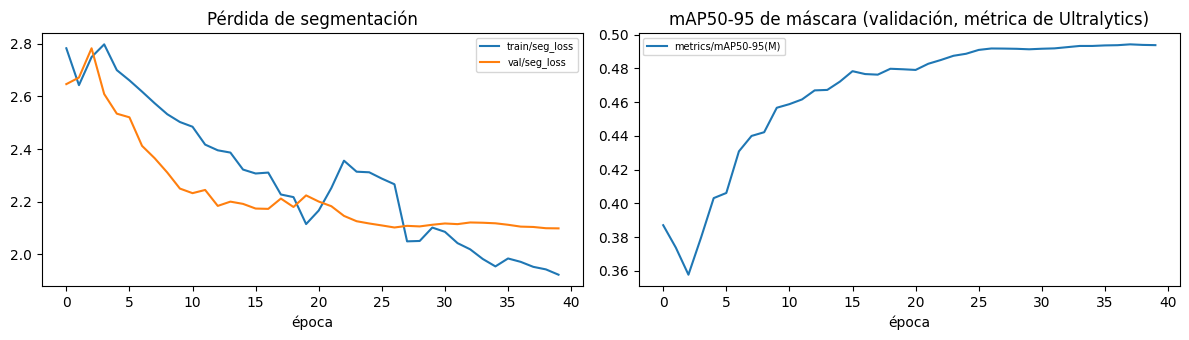

In [7]:
# Curvas de entrenamiento (si existe results.csv)
try:
    import matplotlib.pyplot as plt
    df = pd.read_csv(RUN_DIR / "results.csv"); df.columns = [c.strip() for c in df.columns]
    cm = [c for c in df.columns if "mAP50-95(M)" in c]; lc = [c for c in df.columns if "seg_loss" in c]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for c in lc: ax[0].plot(df[c], label=c)
    for c in cm: ax[1].plot(df[c], label=c)
    ax[0].set_title("Pérdida de segmentación"); ax[1].set_title("mAP50-95 de máscara (validación, métrica de Ultralytics)")
    for a in ax: a.legend(fontsize=7); a.set_xlabel("época")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

---
### ✅ Fin del entrenamiento

Aquí termina la parte de **entrenamiento**: los pesos quedan en `{WORK}/runs/{RUN_NAME}/weights/best.pt` (en tu Drive). Si solo necesitabas el modelo entrenado, puedes detenerte.

Las secciones 3–5 siguientes (predicciones, evaluación con `pycocotools`, latencia y `resultados/A1_*.json`) son la **evaluación** que consumirá el cuadernillo 99. Se ejecutan después, y se pueden repetir sin volver a entrenar (el marcador `DONE.json` evita reentrenar).

## 3. Predicciones y evaluación (`pycocotools`)

Se predice sobre las imágenes de **val** y **test** (sin las excluidas), con `conf=0.001` y máscaras a resolución original. Las predicciones se guardan en formato COCO (RLE) para que el cuadernillo 99 las reutilice. Se evalúa **solo** en modo agnóstico (AP de máscara de «comida»).

In [ ]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(str(BEST))

EVAL_CONF = CFG.get("eval_conf", 0.001)   # umbral bajo para evaluación AP/AR

# --- Memoria: infiere por bloques, limita el lado mayor de la foto y vacía la caché de CUDA ---
# retina_masks=True devuelve la máscara al tamaño de la imagen de entrada. Con fotos muy grandes,
# un solo lote podía pedir decenas de GB (OOM). Aquí se limita el lado mayor y se infiere de una en una.
import gc
from PIL import Image

_pred_max = CFG.get("pred_max_side", max(1024, 2 * CFG["imgsz"]))
PRED_MAX_SIDE = int(_pred_max) if _pred_max else 0  # 0 / None = sin límite
PRED_CHUNK = int(CFG.get("pred_chunk", 16))
PRED_BATCH = int(CFG.get("pred_batch", 1))

def _load_for_pred(path, info):
    im, _, _, _ = fu.load_image_oriented(path, info)
    if PRED_MAX_SIDE and max(im.size) > PRED_MAX_SIDE:
        r = PRED_MAX_SIDE / max(im.size)
        im = im.resize((max(1, round(im.size[0] * r)), max(1, round(im.size[1] * r))), Image.BILINEAR)
    return im

def predict_dets(split, limit=None):
    infos = [im for im in prep.images(split) if im["id"] not in BAD[split]]
    if limit: infos = infos[:limit]
    paths = [YOLO_DIR / "images" / split / im["file_name"] for im in infos]

    pred_kw = dict(imgsz=CFG["imgsz"], conf=EVAL_CONF, max_det=CFG["max_det"], device=DEVICE,
                   retina_masks=True, stream=True, verbose=False, batch=PRED_BATCH)
    if CUDA:
        pred_kw["quantize"] = "fp16"      # reemplaza a half=True (deprecado)

    dets = []
    print(f"  [{split}] {len(infos)} imágenes | max_side={PRED_MAX_SIDE or 'sin límite'} | chunk={PRED_CHUNK} | batch={PRED_BATCH}")
    for start in range(0, len(infos), PRED_CHUNK):
        chunk = infos[start:start + PRED_CHUNK]
        imgs = [_load_for_pred(paths[start + j], info) for j, info in enumerate(chunk)]
        for info, r in zip(chunk, model.predict(imgs, **pred_kw)):
            if r.masks is None or len(r.masks) == 0: continue
            masks = r.masks.data.cpu().numpy() > 0.5
            scores = r.boxes.conf.cpu().numpy(); cls = r.boxes.cls.cpu().numpy().astype(int)
            for m, sc, c in zip(masks, scores, cls):
                if not m.any(): continue
                cat = 1 if CFG["agnostic"] else int(c) + 1          # category_id = class_idx + 1
                dets.append(fu.make_det(info["id"], cat, sc, mask=m, info=info))
        del imgs
        gc.collect()
        if CUDA: torch.cuda.empty_cache()
    return infos, dets


EVAL, PRED_FILES = {}, {}
for s in ("val", "test"):
    t0 = time.time()
    infos, dets = predict_dets(s, limit=50 if CFG["pilot"] else None)
    ids = [im["id"] for im in infos]
    PRED_FILES[s] = str(fu.save_predictions(dets, PRED_DIR / f"{RUN_NAME}_{s}.json"))
    if CFG["agnostic"]:
        EVAL[s] = {"agnostic": fu.evaluate_segm(prep.coco(s, agnostic=True), dets, agnostic=True, img_ids=ids, n_folds=CFG["eval_folds"])}
    else:
        EVAL[s] = fu.evaluate_all(prep.coco(s), dets, img_ids=ids, per_class=(s == "test"), n_folds=CFG["eval_folds"])
    sc_all = [d["score"] for d in dets] if dets and isinstance(dets[0], dict) and "score" in dets[0] else []
    rng = f", score {min(sc_all):.3f}–{max(sc_all):.3f}" if sc_all else ""
    print(f"[{s}] {len(ids)} imágenes, {len(dets):,} detecciones ({len(dets)/max(len(ids),1):.1f}/img){rng}, {time.time()-t0:.0f} s")
    del dets
    gc.collect()
    if CUDA: torch.cuda.empty_cache()

import pandas as pd
rows = []
for s, d in EVAL.items():
    for k, m in d.items():
        rows.append(dict(split=s, modo=k, AP=m["AP"], AP50=m["AP50"], AP75=m["AP75"], APs=m["APs"], APm=m["APm"], APl=m["APl"],
                         AR100=m["AR100"], AP_folds=f"{m.get('AP_fold_mean', float('nan')):.3f}±{m.get('AP_fold_std', float('nan')):.3f}"))
print(pd.DataFrame(rows).round(3).to_string(index=False))

## 4. Eficiencia y referencia de Ultralytics

La latencia es **de extremo a extremo** (lectura, preprocesado, inferencia con máscaras a resolución original y posprocesado), batch = 1 y `conf=0.25`, en la GPU de esta sesión. Debe compararse solo entre modelos medidos en la **misma GPU**.

In [ ]:
sample = str(YOLO_DIR / "images" / "val" / next(im for im in prep.images("val") if im["id"] not in BAD["val"])["file_name"])

_lat_kw = dict(imgsz=CFG["imgsz"], conf=CFG["conf_latency"], max_det=CFG["max_det"], device=DEVICE,
               retina_masks=True, verbose=False)
if CUDA:
    _lat_kw["quantize"] = "fp16"      # reemplaza a half=True (deprecado)

def _one():
    model.predict(sample, **_lat_kw)

fu.reset_gpu_peak()
LAT = fu.measure_latency(_one, warmup=5, iters=30)
EFF = dict(params=fu.count_params(model.model), latency=LAT, gpu_mem_mb=fu.gpu_memory_mb(), gpu=GPU, imgsz=CFG["imgsz"])
print(f"Parámetros: {EFF['params']/1e6:.1f} M | latencia: {LAT['mean_ms']:.1f} ± {LAT['std_ms']:.1f} ms (p95 {LAT['p95_ms']:.1f}) en {GPU}")

# Referencia (NO se usa para comparar): métrica interna de Ultralytics sobre el test exportado
ULTRA = {}
if not CFG["pilot"]:
    try:
        v = model.val(data=DATA_YAML, split="test", imgsz=CFG["imgsz"], batch=CFG["batch"], device=DEVICE, plots=False, verbose=False)
        ULTRA = dict(seg_map50_95=float(v.seg.map), seg_map50=float(v.seg.map50))
        print("Ultralytics (referencia):", ULTRA)
    except Exception as e:
        print("No se pudo obtener la referencia de Ultralytics:", type(e).__name__, e)

## 5. Guardar resultados

In [ ]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model=f"YOLO26{CFG['model_size']}-seg", metrics=EVAL, prep=prep, cfg=CFG, seed=CFG["seed"],
    efficiency=EFF,
    train=dict(pretrained="COCO ("+CFG["weights"]+")", epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"],
               time_s=INFO.get("time_s"), batch=CFG["batch"], imgsz=CFG["imgsz"], pilot=CFG["pilot"]),
    files=dict(weights=str(BEST), pred_val=PRED_FILES["val"], pred_test=PRED_FILES["test"], yolo_data=DATA_YAML),
    notes=("Segmentador agnostico (una clase 'food')." if CFG["agnostic"] else "Segmentador con 323 clases.") + f" Ultralytics ref: {ULTRA}",
    out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

In [ ]:
# Revisión cualitativa: 6 predicciones de test (máscaras de Ultralytics)
try:
    import matplotlib.pyplot as plt
    tests = [im for im in prep.images("test") if im["id"] not in BAD["test"]][:6]

    _viz_kw = dict(imgsz=CFG["imgsz"], conf=0.05 if CFG["pilot"] else 0.25,   # el modelo del piloto apenas da scores altos
                   device=DEVICE, retina_masks=True, verbose=False)
    if CUDA:
        _viz_kw["quantize"] = "fp16"      # reemplaza a half=True (deprecado)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, im in zip(axes.flat, tests):
        r = model.predict(str(YOLO_DIR / "images" / "test" / im["file_name"]), **_viz_kw)[0]
        ax.imshow(r.plot()[..., ::-1]); ax.axis("off"); ax.set_title(im["file_name"], fontsize=8)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Siguientes pasos
- Si el piloto salió bien: `CFG["pilot"] = False` y **Ejecutar todo**. Si Colab se desconecta, vuelve a ejecutar: los datos se vuelven a extraer en el disco local (unos minutos) y el entrenamiento **se reanuda solo** desde `last.pt` en Drive.
- Tras A1, ejecutar **B1** (mismo tamaño de modelo) para la comparación pareada P1 vs P2.
- Los resultados quedan en `{WORK}/resultados/A1_yolo26*.json`; las predicciones COCO en `{WORK}/predicciones/`.